[By : Vaibhav Thakur, BS Economics student, IISER Bhopal, Roll no. 23360](https://github.com/x-SV-x)

Most traditional papers look at how standard commercial banks price climate risk. My novel angle is to simulate what happens after a traditional bank correctly prices climate risk. Recent empirical evidence from the Indian credit market shows that after a localized natural disaster (like a severe flood), traditional bank branches systematically raise interest rates for all borrowers to price in the new risk [(Abhiman Das, Tanmoy Majilla, Sumit Saurav)](https://www.cafral.org.in/sites/default/files/2025-06/172023120545pm_6-tanmoy-majilla_natural_disaster_and_loan_rate_ad_tm_ss.pdf). However, this credit contraction creates a vacuum. Unregulated or lightly regulated shadow banks, specifically Non-Banking Financial Companies (NBFCs), rapidly step in, expanding their lending in flood-affected areas to absorb the risky borrowers that traditional banks rejected [(Sankalp Mathur, Ritwiz Sarma)](https://www.cafral.org.in/sites/default/files/2026-09/disaster_and_household_finance-2.pdf).

My project simulates a local economy to prove a macroeconomic point: strict climate risk regulations on traditional banks do not eliminate systemic climate risk; they merely force it into the opaque shadow banking sector.

This simulation project is divided into the following steps: 

- Phase 1: Generating a synthetic economy
- Phase 2: Simulating climate shock and bank reaction
- Phase 3: Simulating the Shadow Banking Arbitrage/ Shadow Banking spillover
- Phase 4: Visualization and Results

In [2]:
# Dependencies

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Plotting style

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("talk")

# Phase 1: Generating a synthetic economy

**Methodology:** 
This phase initializes a synthetic universe of 10,000 corporate entities to represent a diverse local economy. We use normal and uniform statistical distributions to generate realistic baseline financial profiles for each firm. We then establish each firm's baseline credit health before any climate events occur.
<br>

**Key Variables:**

-   ***revenue*** & ***ebitda_margin***: Simulated financial size and profitability margins for each firm.
-   ***total_debt***: The firm's leverage, calculated as a multiple of revenue.
-   ***flood_vulnerability***: A randomized score from 1 to 100 representing the firm's physical climate risk exposure.
-   ***baseline_rate***: The standard interest rate (8.5%) charged by traditional banks in a normal macroeconomic environment.
-   ***baseline_icr***: The Interest Coverage Ratio ($ICR = EBITDA / Interest Expense$). This is our primary metric for financial health. The firm's **Interest Coverage Ratio (ICR)** measures how many times its EBITDA covers its interest expense.

*We simulate our economy such that it is consistent with the RBI's reports on Interest Coverage Ratio of Indian firms.*

Based on the [Reserve Bank of India's (RBI) Reports](https://www.rbi.org.in/Scripts/PublicationReportDetails.aspx?UrlPage=&ID=1253), the Interest Coverage Ratio (ICR) for Indian firms is generally assessed across different risk thresholds rather than as a single aggregate average, as it varies significantly depending on the sector and size of the firm.


RBI data indicates the following general baseline distribution for listed private non-financial companies in India:

* **Strong Baseline (ICR > 4):** Roughly half of the companies evaluated (between 47% and 52% in recent years) operate with a very comfortable baseline ICR of greater than 4.


* **Moderate Baseline (1 < ICR ≤ 4):** Approximately 25% to 30% of companies maintain an ICR within this middle tier.


* **Vulnerable Baseline (ICR ≤ 1):** Around 20% to 35% of companies historically operate with an ICR of 1 or below, meaning their operating profits are insufficient to cover their current debt interest expenses.



As a general financial benchmark, an ICR falling below 1.5 is widely considered a sign of acute financial stress for a company, signaling that the firm has a heavy debt burden and a high probability of defaulting on its interest obligations.


*Source: [RBI's report dated 28 Dec, 2023](https://www.rbi.org.in/Scripts/PublicationReportDetails.aspx?UrlPage=&ID=1253)*


**Table 1.3: Debt Share of Firms Below/ Above ICR Threshold Values** 

| Items | 2016-17 | 2017-18 | 2018-19 | 2019-20 | 2020-21 | 2021-22 | 2022-23 | H1: 2023-24 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| No of Companies | 3,238 | 3,231 | 3,205 | 3,163 | 3,103 | 2,963 | 2,990 | 2,880 |
| ICR <=1 (per cent) | 35.5 | 34.2 | 34.1 | 37.6 | 34.7 | 32.6 | 21.0 | 21.9 |
| 1 < ICR <= 4 (per cent) | 34.8 | 34.3 | 27.6 | 25.2 | 31.5 | 15.2 | 27.9 | 30.5 |
| ICR > 4 (per cent) | 29.6 | 31.5 | 38.3 | 37.2 | 33.8 | 52.2 | 51.2 | 47.6 |

*Sources: Capitaline and RBI staff calculations.*

**How to Interpret the Interest Coverage Ratio (ICR)**


| ICR | Interpretation | Meaning |
| :---: | :--- | :--- |
| **ICR < 1** | **Insufficient Coverage** | EBITDA is lower than interest expense. The firm cannot cover all its interest costs from operating earnings alone. |
| **ICR 1–2** | **Limited Buffer** | Interest is covered, but a decline in earnings or increase in borrowing costs could create financial pressure. |
| **ICR > 2** | **Larger Coverage Buffer** | EBITDA is more than twice interest expense, providing more room to absorb financial shocks, all else equal. |

In [5]:
print(" PHASE 1: GENERATING A SYNTHETIC ECONOMY ")

import pandas as pd
import numpy as np

np.random.seed(101) 
n_firms = 10000

# 1.1 Generate Base Financials for 10,000 Firms

# Revenue in millions of Rupees, normal distribution
revenue = np.random.normal(loc=500, scale=150, size=n_firms)
revenue = np.clip(revenue, 100, 2000) # Ensures no negative revenues

# EBITDA Margin (Operating Profit Margin) between 10% and 30%
ebitda_margin = np.random.uniform(0.10, 0.30, size=n_firms)
ebitda = revenue * ebitda_margin

# Total Debt (Leverage) - Segmented to match RBI ICR distribution targets
u = np.random.rand(n_firms)
debt_to_revenue = np.zeros(n_firms)

# ~50% Strong (ICR > 4) -> Assigned lower debt multiples
mask_strong = u < 0.50
debt_to_revenue[mask_strong] = np.random.uniform(0.1, 0.6, size=mask_strong.sum())

# ~25% Moderate (1 < ICR <= 4) -> Assigned medium debt multiples
mask_moderate = (u >= 0.50) & (u <= 0.75)
debt_to_revenue[mask_moderate] = np.random.uniform(0.6, 2.5, size=mask_moderate.sum())

# ~25% Vulnerable (ICR <= 1) -> Assigned higher debt multiples
mask_vulnerable = u > 0.75
debt_to_revenue[mask_vulnerable] = np.random.uniform(2.5, 4.5, size=mask_vulnerable.sum())

total_debt = revenue * debt_to_revenue

# 1.2 Assign Climate Risk (Flood Vulnerability Score 1-100)

flood_vulnerability = np.random.randint(1, 101, size=n_firms)

# 1.3 Baseline Banking Profile (Pre-Shock)

baseline_rate = 0.085 # 8.5% average traditional bank loan rate
interest_expense = total_debt * baseline_rate
baseline_icr = ebitda / interest_expense # Interest Coverage Ratio

# DataFrame

df = pd.DataFrame({
    'Firm_ID': range(1, n_firms + 1),
    'Revenue': revenue,
    'EBITDA': ebitda,
    'Total_Debt': total_debt,
    'Flood_Vulnerability': flood_vulnerability,
    'Baseline_Interest_Expense': interest_expense,
    'Baseline_ICR': baseline_icr
})

print(f"Generated financial profiles for {n_firms} synthetic firms.")
print(f"Strong Baseline (ICR > 4): {(df['Baseline_ICR'] > 4).sum()} firms ({(df['Baseline_ICR'] > 4).sum()/n_firms*100:.1f}%)")
print(f"Moderate Baseline (1 < ICR <= 4): {((df['Baseline_ICR'] > 1) & (df['Baseline_ICR'] <= 4)).sum()} firms ({((df['Baseline_ICR'] > 1) & (df['Baseline_ICR'] <= 4)).sum()/n_firms*100:.1f}%)")
print(f"Vulnerable Baseline (ICR <= 1): {(df['Baseline_ICR'] <= 1).sum()} firms ({(df['Baseline_ICR'] <= 1).sum()/n_firms*100:.1f}%)\n")

 PHASE 1: GENERATING A SYNTHETIC ECONOMY 
Generated financial profiles for 10000 synthetic firms.
Strong Baseline (ICR > 4): 4380 firms (43.8%)
Moderate Baseline (1 < ICR <= 4): 2899 firms (29.0%)
Vulnerable Baseline (ICR <= 1): 2721 firms (27.2%)



In [6]:
# Simulated dataset after Phase 1
df

,Firm_ID,Revenue,EBITDA,Total_Debt,Flood_Vulnerability,Baseline_Interest_Expense,Baseline_ICR
0,1,906.027476,144.250235,1137.996096,2,96.729668,1.491272
1,2,594.219906,130.944611,300.868018,43,25.573782,5.120268
2,3,636.195417,90.459613,102.321418,62,8.697321,10.400860
3,4,575.573863,131.570884,1253.988631,2,106.589034,1.234375
4,5,597.667692,171.915680,171.452178,96,14.573435,11.796510
...,...,...,...,...,...,...,...
9995,9996,493.114572,59.423721,984.465739,30,83.679588,0.710134
9996,9997,507.803586,65.578099,236.042205,97,20.063587,3.268513
9997,9998,620.447869,114.976870,833.735111,77,70.867484,1.622421
9998,9999,651.604744,186.605469,1724.742473,20,146.603110,1.272862


In [7]:
# Summary statistics
df.describe()

,Firm_ID,Revenue,EBITDA,Total_Debt,Flood_Vulnerability,Baseline_Interest_Expense,Baseline_ICR
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,502.375788,100.826358,717.894951,50.510600,61.021071,4.862628
std,2886.89568,151.334776,42.610649,735.199878,28.552906,62.491990,5.294833
min,1.00000,100.000000,10.806847,11.092063,1.000000,0.942825,0.265337
25%,2500.75000,398.669332,68.683534,162.706774,26.000000,13.830076,0.928975
50%,5000.50000,501.358201,95.039859,336.095622,51.000000,28.568128,3.118729
75%,7500.25000,604.402655,128.453892,1168.661435,75.000000,99.336222,6.705314
max,10000.00000,1139.093225,296.345709,4484.928590,100.000000,381.218930,33.356524


The financial variables and flood vulnerability scores are generated independently. As a result, flood vulnerability does not directly affect baseline financial health.

# Phase 2: Simulating climate shock and bank reaction

**Methodology:** 
This phase introduces a physical climate shock (a severe flood) and models the subsequent behavioral reaction of traditional commercial banks. The model directly links the firm's vulnerability score to its revenue destruction. We then simulate traditional banks de-risking their portfolios by hiking interest rates for vulnerable borrowers and strictly cutting off credit to firms that fall below a safe regulatory health threshold.


**Key Variables:**

-   ***shock_severity***: A percentage drop in revenue scaled directly to the firm's ***flood_vulnerability*** score (up to a 35% drop).
-   ***Bank_Rate_Post_Shock***: The new interest rate. Banks hike this by 50 basis points for firms with a vulnerability score > 50.
-   ***Stressed_Bank_ICR***: The recalculated Interest Coverage Ratio incorporating both the revenue shock and the higher interest burden.
-   ***Bank_Approved***: A boolean flag. Traditional banks reject the loan renewal if the firm's stressed ICR falls below $1.5$.

In [9]:
print(" PHASE 2: SIMULATING CLIMATE SHOCK (FLOOD) ")

# 2.1 The Physical Shock: Flood severely impacts high-vulnerability firms

# Revenue drops up to 35% for the most vulnerable firms

shock_severity = (df['Flood_Vulnerability'] / 100) * 0.35
df['Shocked_Revenue'] = df['Revenue'] * (1 - shock_severity)
df['Shocked_EBITDA'] = df['Shocked_Revenue'] * ebitda_margin

# 2.2 Traditional Bank Reaction: De-risking

# Banks hike rates by 50 basis points (0.005) for vulnerable firms (Score > 50)
df['Bank_Rate_Post_Shock'] = np.where(df['Flood_Vulnerability'] > 50, baseline_rate + 0.005, baseline_rate)
df['Bank_Interest_Post_Shock'] = df['Total_Debt'] * df['Bank_Rate_Post_Shock']

# 2.3 Recalculate Health (Stressed ICR)

df['Stressed_Bank_ICR'] = df['Shocked_EBITDA'] / df['Bank_Interest_Post_Shock']

# 2.4 Bank Decision: Deny renewal if Stressed ICR < 1.5 (Strict regulatory cutoff)

df['Bank_Approved'] = df['Stressed_Bank_ICR'] >= 1.5
rejected_count = (~df['Bank_Approved']).sum()

print(f"Climate shock applied. Traditional banks raised rates by 50 bps for vulnerable firms.")
print(f"Traditional banks rejected {rejected_count} firms due to deteriorating credit health.\n")

 PHASE 2: SIMULATING CLIMATE SHOCK (FLOOD) 
Climate shock applied. Traditional banks raised rates by 50 bps for vulnerable firms.
Traditional banks rejected 4104 firms due to deteriorating credit health.



In [10]:
# Simulated dataset after Phase 2
df

,Firm_ID,Revenue,EBITDA,Total_Debt,Flood_Vulnerability,Baseline_Interest_Expense,Baseline_ICR,Shocked_Revenue,Shocked_EBITDA,Bank_Rate_Post_Shock,Bank_Interest_Post_Shock,Stressed_Bank_ICR,Bank_Approved
0,1,906.027476,144.250235,1137.996096,2,96.729668,1.491272,899.685284,143.240483,0.085,96.729668,1.480833,False
1,2,594.219906,130.944611,300.868018,43,25.573782,5.120268,504.789810,111.237447,0.085,25.573782,4.349668,True
2,3,636.195417,90.459613,102.321418,62,8.697321,10.400860,498.141011,70.829877,0.090,9.208928,7.691436,True
3,4,575.573863,131.570884,1253.988631,2,106.589034,1.234375,571.544846,130.649888,0.085,106.589034,1.225735,False
4,5,597.667692,171.915680,171.452178,96,14.573435,11.796510,396.851348,114.152012,0.090,15.430696,7.397723,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,493.114572,59.423721,984.465739,30,83.679588,0.710134,441.337542,53.184230,0.085,83.679588,0.635570,False
9996,9997,507.803586,65.578099,236.042205,97,20.063587,3.268513,335.404268,43.314335,0.090,21.243798,2.038917,True
9997,9998,620.447869,114.976870,833.735111,77,70.867484,1.622421,453.237168,83.990604,0.090,75.036160,1.119335,False
9998,9999,651.604744,186.605469,1724.742473,20,146.603110,1.272862,605.992412,173.543087,0.085,146.603110,1.183761,False


In [15]:
# Summary statistics after the climate shock
df.describe()

,Firm_ID,Revenue,EBITDA,Total_Debt,Flood_Vulnerability,Baseline_Interest_Expense,Baseline_ICR,Shocked_Revenue,Shocked_EBITDA,Bank_Rate_Post_Shock,Bank_Interest_Post_Shock,Stressed_Bank_ICR,Final_Interest_Expense,Final_ICR
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,502.375788,100.826358,717.894951,50.510600,61.021071,4.862628,413.753220,83.040800,0.087507,62.819996,3.901649,84.658305,3.813584
std,2886.89568,151.334776,42.610649,735.199878,28.552906,62.491990,5.294833,135.934318,36.820156,0.002500,64.379232,4.336339,94.544374,4.399422
min,1.00000,100.000000,10.806847,11.092063,1.000000,0.942825,0.265337,65.350000,7.327042,0.085000,0.942825,0.175438,0.942825,0.126315
25%,2500.75000,398.669332,68.683534,162.706774,26.000000,13.830076,0.928975,318.986951,55.388995,0.085000,14.214210,0.747016,14.240288,0.520459
50%,5000.50000,501.358201,95.039859,336.095622,51.000000,28.568128,3.118729,406.990576,77.458444,0.090000,29.376347,2.453253,29.973833,2.453253
75%,7500.25000,604.402655,128.453892,1168.661435,75.000000,99.336222,6.705314,501.814713,106.232702,0.090000,101.896685,5.364617,145.707467,5.364617
max,10000.00000,1139.093225,296.345709,4484.928590,100.000000,381.218930,33.356524,1013.188142,249.976707,0.090000,381.218930,31.187908,560.616074,31.187908


# Phase 3: Shadow banking (NBFC) spillover

**Methodology:** 
This phase simulates the macroeconomic spillover effect. Firms that are cut off by traditional banks do not simply disappear; they are forced to seek funding in the unregulated shadow banking sector (Non-Banking Financial Companies, or NBFCs). The model assumes NBFCs will absorb these risky borrowers but will charge a massive "climate risk premium," leading to a surge in technical defaults.
<br>

**Key Variables:**

-   ***nbfc_rate***: The predatory shadow banking interest rate, modeled as a 400 basis point (4.0%) premium over the baseline rate.
-   ***Final_Lender***: Tracks whether the firm stayed with a 'Traditional Bank' or was pushed to a 'Shadow Bank'.
-   ***Final_ICR***: The ultimate Interest Coverage Ratio after accounting for NBFC interest rates.
-   ***Default***: A boolean flag triggered if a firm's `Final_ICR` drops below $1.0$, indicating it no longer generates enough operating profit to service its shadow debt.

In [18]:
print(" PHASE 3: SHADOW BANKING SPILLOVER ")

# 3.1 NBFCs absorb the rejected firms but charge a massive risk premium (400 bps / 4.0%) 

nbfc_rate = baseline_rate + 0.040 
df['Final_Lender'] = np.where(df['Bank_Approved'], 'Traditional Bank', 'Shadow Bank (NBFC)')

# Calculating NBFC interest burden

df['Final_Interest_Expense'] = np.where(
    df['Bank_Approved'], 
    df['Bank_Interest_Post_Shock'], 
    df['Total_Debt'] * nbfc_rate
)

# 3.2 Final Firm Health and Default Calculation

df['Final_ICR'] = df['Shocked_EBITDA'] / df['Final_Interest_Expense']

# A firm defaults if its final ICR drops below 1.0 (cannot cover interest payments)

df['Default'] = df['Final_ICR'] < 1.0

nbfc_count = (df['Final_Lender'] == 'Shadow Bank (NBFC)').sum()
default_count = df['Default'].sum()

print(f"Shadow Banks absorbed {nbfc_count} rejected firms.")
print(f"Total Defaults caused by predatory shadow rates: {default_count} firms.\n")

 PHASE 3: SHADOW BANKING SPILLOVER 
Shadow Banks absorbed 4104 rejected firms.
Total Defaults caused by predatory shadow rates: 4013 firms.



In [19]:
# Simulated dataset after Phase 3
df

,Firm_ID,Revenue,EBITDA,Total_Debt,Flood_Vulnerability,Baseline_Interest_Expense,Baseline_ICR,Shocked_Revenue,Shocked_EBITDA,Bank_Rate_Post_Shock,Bank_Interest_Post_Shock,Stressed_Bank_ICR,Bank_Approved,Final_Lender,Final_Interest_Expense,Final_ICR,Default
0,1,906.027476,144.250235,1137.996096,2,96.729668,1.491272,899.685284,143.240483,0.085,96.729668,1.480833,False,Shadow Bank (NBFC),142.249512,1.006966,False
1,2,594.219906,130.944611,300.868018,43,25.573782,5.120268,504.789810,111.237447,0.085,25.573782,4.349668,True,Traditional Bank,25.573782,4.349668,False
2,3,636.195417,90.459613,102.321418,62,8.697321,10.400860,498.141011,70.829877,0.090,9.208928,7.691436,True,Traditional Bank,9.208928,7.691436,False
3,4,575.573863,131.570884,1253.988631,2,106.589034,1.234375,571.544846,130.649888,0.085,106.589034,1.225735,False,Shadow Bank (NBFC),156.748579,0.833500,True
4,5,597.667692,171.915680,171.452178,96,14.573435,11.796510,396.851348,114.152012,0.090,15.430696,7.397723,True,Traditional Bank,15.430696,7.397723,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,493.114572,59.423721,984.465739,30,83.679588,0.710134,441.337542,53.184230,0.085,83.679588,0.635570,False,Shadow Bank (NBFC),123.058217,0.432188,True
9996,9997,507.803586,65.578099,236.042205,97,20.063587,3.268513,335.404268,43.314335,0.090,21.243798,2.038917,True,Traditional Bank,21.243798,2.038917,False
9997,9998,620.447869,114.976870,833.735111,77,70.867484,1.622421,453.237168,83.990604,0.090,75.036160,1.119335,False,Shadow Bank (NBFC),104.216889,0.805921,True
9998,9999,651.604744,186.605469,1724.742473,20,146.603110,1.272862,605.992412,173.543087,0.085,146.603110,1.183761,False,Shadow Bank (NBFC),215.592809,0.804958,True


In [14]:
# Summary statistics after Phase 3:
df.describe()

,Firm_ID,Revenue,EBITDA,Total_Debt,Flood_Vulnerability,Baseline_Interest_Expense,Baseline_ICR,Shocked_Revenue,Shocked_EBITDA,Bank_Rate_Post_Shock,Bank_Interest_Post_Shock,Stressed_Bank_ICR,Final_Interest_Expense,Final_ICR
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,502.375788,100.826358,717.894951,50.510600,61.021071,4.862628,413.753220,83.040800,0.087507,62.819996,3.901649,84.658305,3.813584
std,2886.89568,151.334776,42.610649,735.199878,28.552906,62.491990,5.294833,135.934318,36.820156,0.002500,64.379232,4.336339,94.544374,4.399422
min,1.00000,100.000000,10.806847,11.092063,1.000000,0.942825,0.265337,65.350000,7.327042,0.085000,0.942825,0.175438,0.942825,0.126315
25%,2500.75000,398.669332,68.683534,162.706774,26.000000,13.830076,0.928975,318.986951,55.388995,0.085000,14.214210,0.747016,14.240288,0.520459
50%,5000.50000,501.358201,95.039859,336.095622,51.000000,28.568128,3.118729,406.990576,77.458444,0.090000,29.376347,2.453253,29.973833,2.453253
75%,7500.25000,604.402655,128.453892,1168.661435,75.000000,99.336222,6.705314,501.814713,106.232702,0.090000,101.896685,5.364617,145.707467,5.364617
max,10000.00000,1139.093225,296.345709,4484.928590,100.000000,381.218930,33.356524,1013.188142,249.976707,0.090000,381.218930,31.187908,560.616074,31.187908


# Phase 4: Visualization and Results

**Methodology:** 
This final phase aggregates the firm-level microdata into macroeconomic totals to prove our thesis. I use ***matplotlib*** and ***seaborn*** to generate three visual proofs: a portfolio migration bar chart, a shadow-bank default pie chart, and a density distribution of corporate interest burdens. 


**Key Outputs:**

-   **Migration of Loan Portfolios:** Visually demonstrates the credit vacuum, how traditional bank loan volume shrinks while shadow bank volume explodes.
-   **Survival Rate in Shadow Banking:** Highlights the fatal consequences of the risk premium, showing the exact percentage of defaults within the NBFC sector.
-   **Shift in Interest Expense Burden:** A Kernel Density Estimate (KDE) plot showing the systemic rightward shift in debt-servicing costs across the entire simulated economy.

## Visualization

### Plot 1: Migration of Loan Portfolios

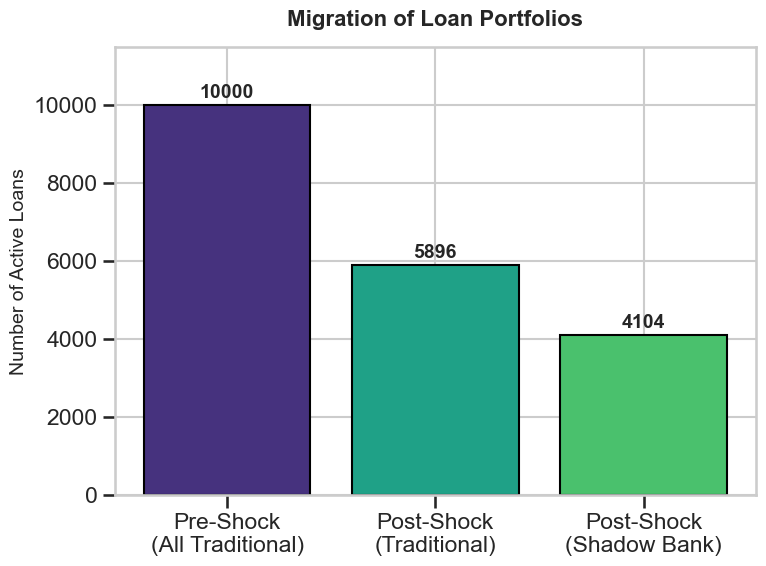

In [11]:
# Viridis palette
viridis_colors = sns.color_palette("viridis", 6)

# Bar chart
plt.figure(figsize=(8, 6))

labels = ['Pre-Shock\n(All Traditional)', 'Post-Shock\n(Traditional)', 'Post-Shock\n(Shadow Bank)']
loan_counts = [n_firms, df['Bank_Approved'].sum(), nbfc_count]

bar_colors = [viridis_colors[0], viridis_colors[3], viridis_colors[4]] 

plt.bar(labels, loan_counts, color=bar_colors, edgecolor='black', linewidth=1.5)
for i, v in enumerate(loan_counts):
    plt.text(i, v + 200, str(v), ha='center', fontweight='bold', fontsize=14)

plt.title('Migration of Loan Portfolios', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('Number of Active Loans', fontsize=14)
plt.ylim(0, n_firms + 1500) 

plt.tight_layout()
plt.show()

### Plot 2: Survival Rate in Shadow Banking

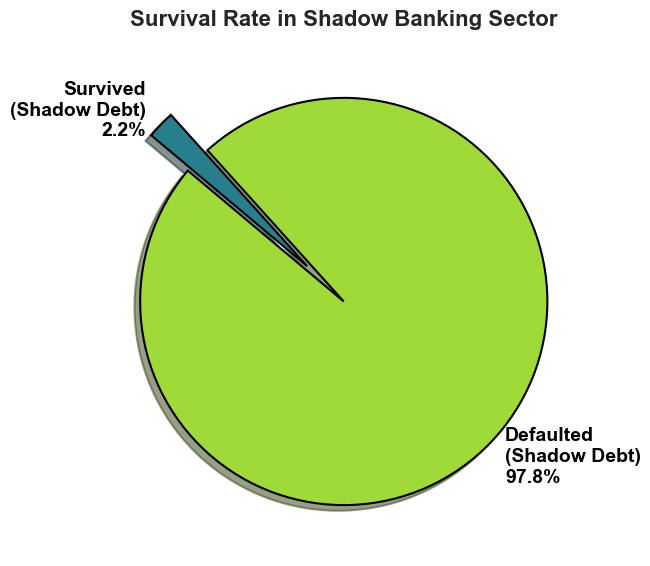

In [12]:
plt.figure(figsize=(8, 6))

# Defaults specifically within the Shadow Banking portfolio

nbfc_defaults = df[(df['Final_Lender'] == 'Shadow Bank (NBFC)') & (df['Default'] == True)].shape[0]
nbfc_survivals = nbfc_count - nbfc_defaults

# Calculate percentages 

pct_default = (nbfc_defaults / nbfc_count) * 100
pct_survive = (nbfc_survivals / nbfc_count) * 100

pie_labels = [f'Defaulted\n(Shadow Debt)\n{pct_default:.1f}%', 
              f'Survived\n(Shadow Debt)\n{pct_survive:.1f}%']
pie_sizes = [nbfc_defaults, nbfc_survivals]

pie_colors = [viridis_colors[5], viridis_colors[2]] 

explode = (0, 0.25)

plt.pie(pie_sizes, explode=explode, labels=pie_labels, colors=pie_colors, 
            shadow=True, startangle=140, 
            textprops={'fontsize': 14, 'weight': 'bold', 'color': 'black'},
            wedgeprops={'edgecolor': 'black', 'linewidth': 1.5}) 

plt.title('Survival Rate in Shadow Banking Sector', fontsize=16, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

### Plot 3: Shift in Interest Expense Burden

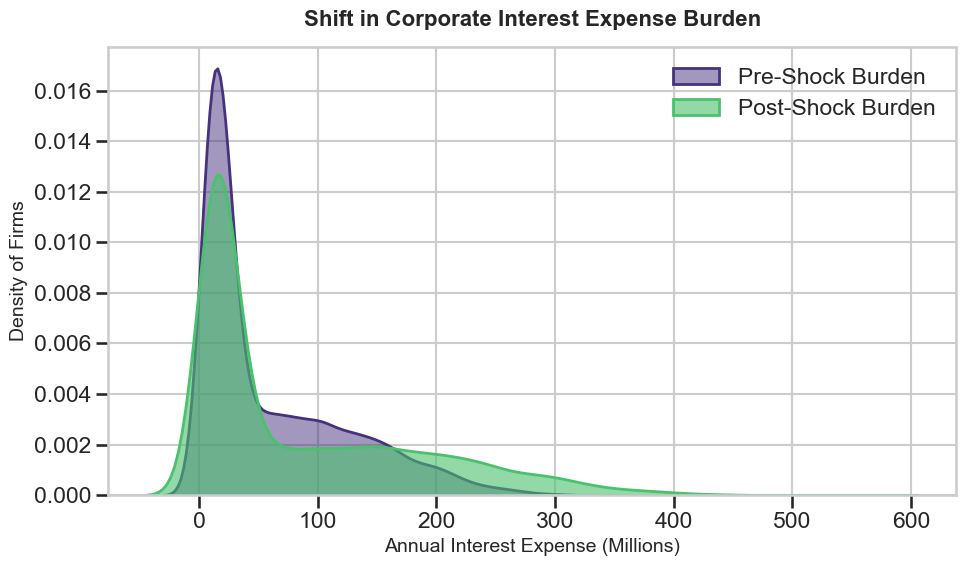

In [13]:
plt.figure(figsize=(10, 6))

# KDE plot

sns.kdeplot(data=df, x='Baseline_Interest_Expense', color=viridis_colors[0], 
            label='Pre-Shock Burden', fill=True, alpha=0.5, linewidth=2)
sns.kdeplot(data=df, x='Final_Interest_Expense', color=viridis_colors[4], 
            label='Post-Shock Burden', fill=True, alpha=0.6, linewidth=2)

plt.title('Shift in Corporate Interest Expense Burden', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Annual Interest Expense (Millions)', fontsize=14)
plt.ylabel('Density of Firms', fontsize=14)
plt.legend()

plt.tight_layout()
plt.show()

## Results

In [ ]:
print(f"1. I simulated a synthetic economy of {n_firms} firms to test regulatory climate risk behavior.")
print(f"2. After a simulated severe flood shock, traditional banks aggressively de-risked. They hiked interest rates by 50 basis points for highly vulnerable firms and outright rejected {nbfc_count} firms whose Interest Coverage Ratios dropped below 1.5.")
print(f"3. While the traditional banking sector looked safer on paper, the macroeconomic risk did not disappear. It migrated.")
print(f"4. Unregulated Shadow Banks (NBFCs) stepped in to absorb all {nbfc_count} rejected firms, but charged an exorbitant 400 basis point risk premium.")
print(f"5. Because highly vulnerable firms were forced to take on extremely expensive shadow debt just to survive the shock, {nbfc_defaults} of them collapsed into default.")
print("6. CONCLUSION: Traditional bank climate stress tests are fundamentally flawed if they ignore shadow banking. Pushing climate risk out of regulated banks actually increases total systemic defaults.")

1. I simulated a synthetic economy of 10000 firms to test regulatory climate risk behavior.
2. After a simulated severe flood shock, traditional banks aggressively de-risked. They hiked interest rates by 50 basis points for highly vulnerable firms and outright rejected 4104 firms whose Interest Coverage Ratios dropped below 1.5.
3. While the traditional banking sector looked safer on paper, the macroeconomic risk did not disappear. It migrated.
4. Unregulated Shadow Banks (NBFCs) stepped in to absorb all 4104 rejected firms, but charged an exorbitant 400 basis point risk premium.
5. Because highly vulnerable firms were forced to take on extremely expensive shadow debt just to survive the shock, 4013 of them collapsed into default.
6. ***CONCLUSION***: Traditional bank climate stress tests are fundamentally flawed if they ignore shadow banking. Pushing climate risk out of regulated banks actually increases total systemic defaults.